# 07 · Compare incoming batches

Each batch is compared only with earlier batches. The street/city/state match is a **proxy**, not a verified property identifier. Exact matches compare every column, including price.

## Imports

In [1]:
import gc
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)


## Saved batches

In [2]:
DATA = Path('../data')
GROUP = int(os.environ['DATA_API_GROUP'])
files = sorted(DATA.glob(f'group-{GROUP}-*.json'))
if len(files) < 2:
    raise ValueError('At least two saved batches are needed.')
NUMERIC = ['bed', 'bath', 'acre_lot', 'house_size']
CATEGORICAL = ['city', 'state', 'status']
REQUIRED = set(NUMERIC + CATEGORICAL + ['price', 'street'])
SAMPLE_SIZE = 50_000
rng = np.random.default_rng(42)
print('Saved responses:', len(files))


Saved responses: 6


## Helpers

In [3]:
def load_batch(path, previous):
    with path.open() as file:
        response = json.load(file)
    number = response['batch_number']
    if response.get('group_number') != GROUP or (previous is not None and number <= previous):
        raise ValueError(f'Check group and batch order: {path.name}')
    frame = pd.DataFrame(response['data'])
    missing = sorted(REQUIRED - set(frame.columns))
    if frame.empty or missing:
        raise ValueError(f'Batch {number}: empty or missing columns {missing}')
    return number, frame

def add_sample(sample, frame):
    # Random priorities give every previous valid row the same chance of being kept.
    part = frame[NUMERIC].copy()
    part['_random'] = rng.random(len(part))
    if sample is not None:
        part = pd.concat([sample, part], ignore_index=True)
    return part.nsmallest(SAMPLE_SIZE, '_random').reset_index(drop=True)

def psi(reference, current, discrete=False):
    ref = pd.to_numeric(reference, errors='coerce').dropna().to_numpy()
    cur = pd.to_numeric(current, errors='coerce').dropna().to_numpy()
    if len(ref) < 2 or len(cur) < 2:
        return np.nan
    if discrete:
        values = np.union1d(ref, cur)
        r = pd.Series(ref).value_counts(normalize=True).reindex(values, fill_value=0).to_numpy()
        n = pd.Series(cur).value_counts(normalize=True).reindex(values, fill_value=0).to_numpy()
    else:
        edges = np.unique(np.quantile(ref, np.linspace(0, 1, 11)))
        if len(edges) < 2:
            return np.nan
        edges[0], edges[-1] = -np.inf, np.inf
        r = np.histogram(ref, bins=edges)[0] / len(ref)
        n = np.histogram(cur, bins=edges)[0] / len(cur)
    r, n = np.maximum(r, 1e-6), np.maximum(n, 1e-6)
    return float(((n - r) * np.log(n / r)).sum())

def row_hashes(frame, columns):
    return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


## Compare and plot

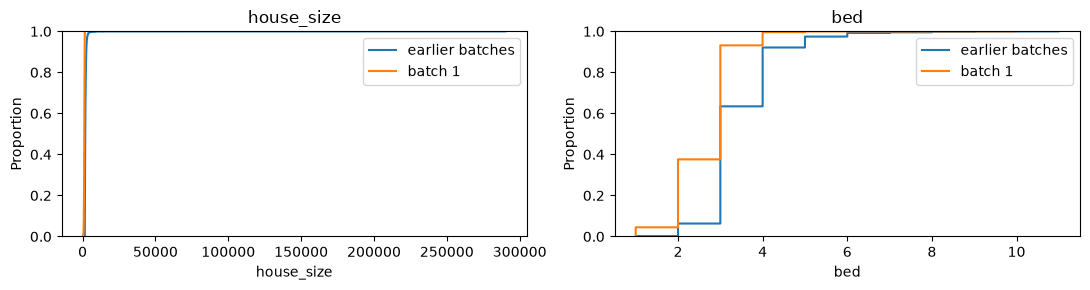

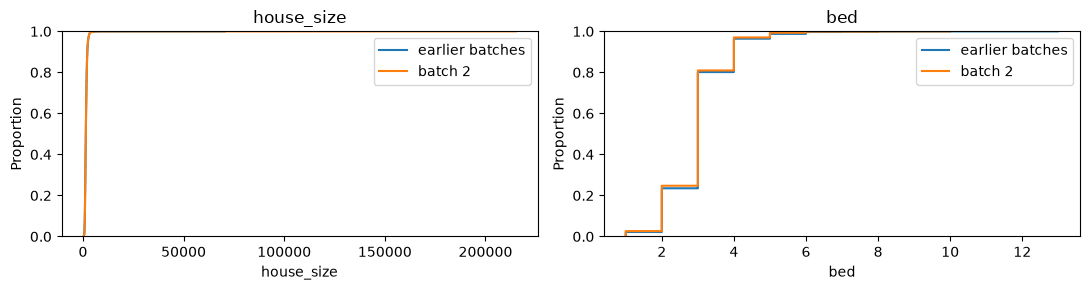

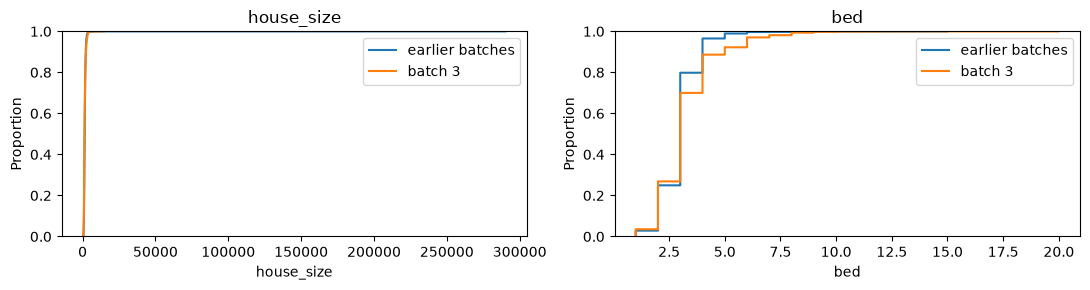

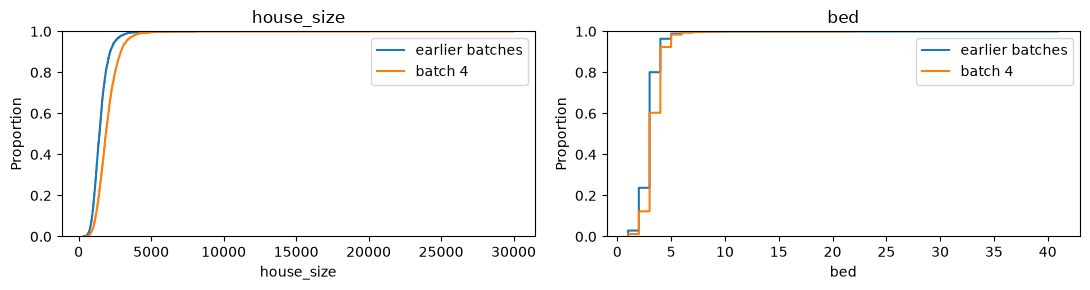

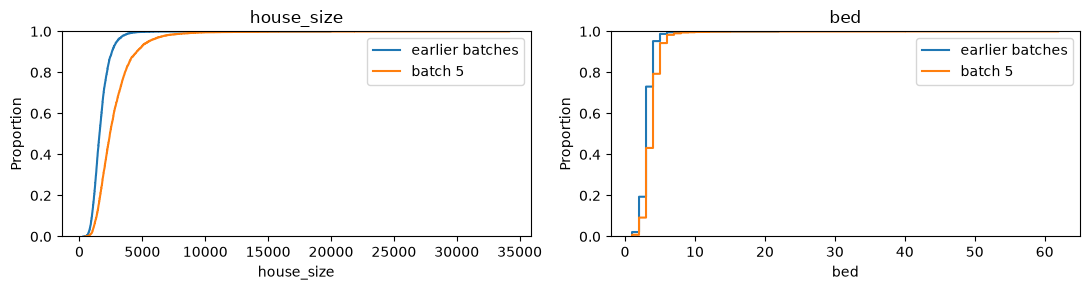

,batch,previous_rows,rows,within_batch_duplicates,exact_seen_before,new_exact_%,proxy_seen_before_%,valid_price_%,new_city_%,max_PSI
0,0,0,73784,0,0,100.0,NaN,100.0,NaN,NaN
1,1,73784,94551,0,0,100.0,0.01,100.0,5.20,12.464
2,2,168335,230366,0,0,100.0,9.56,100.0,2.35,0.006
3,3,398701,4055,0,0,100.0,0.00,100.0,27.08,0.209
4,4,402756,320696,0,0,100.0,0.02,100.0,2.16,0.621
5,5,723452,361457,0,0,100.0,0.07,100.0,3.93,1.072


In [4]:
seen_rows = np.array([], dtype='uint64')
seen_properties = np.array([], dtype='uint64')
known = {name: set() for name in CATEGORICAL}
history_sample = None
history_count = 0
columns = None
previous = None
rows = []

for path in files:
    number, current = load_batch(path, previous)
    previous = number
    if columns is None:
        columns = sorted(current.columns)
    if sorted(current.columns) != columns:
        raise ValueError(f'Batch {number}: schema changed; inspect before continuing')
    hashes = row_hashes(current, columns)
    within = pd.Series(hashes).duplicated().to_numpy()
    earlier = ~within & np.isin(hashes, seen_rows)
    new = ~within & ~earlier
    valid = pd.to_numeric(current['price'], errors='coerce').gt(0)

    # Proxy only: street/city/state may refer to multiple properties.
    proxy_cols = ['street', 'city', 'state']
    has_proxy = current[proxy_cols].notna().all(axis=1).to_numpy()
    proxy_hashes = row_hashes(current.loc[has_proxy], proxy_cols)
    repeat_proxy = np.isin(proxy_hashes, seen_properties)
    proxy_pct = 100 * repeat_proxy.mean() if len(proxy_hashes) and history_count else np.nan

    new_city = np.nan
    max_psi = np.nan
    if history_sample is not None:
        cities = current.loc[valid, 'city'].dropna().astype(str)
        new_city = 100 * (~cities.isin(known['city'])).mean() if len(cities) else np.nan
        drift = {col: psi(history_sample[col], current.loc[valid, col], col in ['bed', 'bath']) for col in NUMERIC}
        values = [value for value in drift.values() if np.isfinite(value)]
        max_psi = max(values) if values else np.nan
        fig, axes = plt.subplots(1, 2, figsize=(11, 3))
        for ax, col in zip(axes, ['house_size', 'bed']):
            for label, series in [('earlier batches', history_sample[col]), (f'batch {number}', current.loc[valid, col])]:
                series = pd.to_numeric(series, errors='coerce').dropna()
                if len(series):
                    sns.ecdfplot(series.sample(min(len(series), 5000), random_state=42), label=label, ax=ax)
            ax.set_title(col); ax.legend()
        plt.tight_layout(); plt.show()
    rows.append({'batch': number, 'previous_rows': history_count, 'rows': len(current),
                 'within_batch_duplicates': int(within.sum()), 'exact_seen_before': int(earlier.sum()),
                 'new_exact_%': round(100 * new.mean(), 2), 'proxy_seen_before_%': round(proxy_pct, 2),
                 'valid_price_%': round(100 * valid.mean(), 2),
                 'new_city_%': round(new_city, 2), 'max_PSI': round(max_psi, 3)})
    seen_rows = np.union1d(seen_rows, hashes)
    seen_properties = np.union1d(seen_properties, proxy_hashes)
    history_count += len(current)
    valid_rows = current.loc[valid]
    if len(valid_rows):
        history_sample = add_sample(history_sample, valid_rows)
        for col in CATEGORICAL:
            known[col].update(valid_rows[col].dropna().astype(str).unique())
    del current, valid_rows, hashes, proxy_hashes
    gc.collect()
results = pd.DataFrame(rows)
display(results)


Plots use samples; percentage and duplicate counts use the complete batches. Distribution reference samples are bounded to reduce memory use.